# **11.  Evaluación y comparación de modelos.**

Temas selectos de aprendizaje de máquina \
Ana Luisa Llamas Martinez

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## 11.1 Preparación.

In [4]:
housing = fetch_california_housing(as_frame = True)

X = housing.data
y = housing.target

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

## 11.2 ¿Contra qué debemos comparar?

In [6]:
baseline = DummyRegressor(strategy="mean")

## 11.3 Modelos que compararemos.

In [7]:
modelos = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators = 200, random_state=42, n_jobs = -1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2, random_state=42)
}

## 11.4 Una estrategia común de Cross-Validation.

In [8]:
cv = KFold(n_splits=5, random_state=42, shuffle=True)

## 11.5 Evaluaremos más de una métrica.

In [9]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

## 11.6 Comparación mediante Cross-Validation.

In [10]:
resultados = []

for nombre, modelo in modelos.items():
    cv_result = cross_validate(
        modelo,
        X_train,
        y_train,
        cv = cv,
        scoring=scoring,
        n_jobs= -1
    )
    resultados.append({
        "Modelo": nombre,
        "MAE_CV": -cv_result["test_MAE"].mean(),
        "MAE_SD": cv_result["test_MAE"].std(),
        "RMSE_CV": -cv_result["test_RMSE"].mean(),
        "RMSE_SD": cv_result["test_RMSE"].std(),
        "R2_CV": cv_result["test_R2"].mean(),
        "R2_SD": cv_result["test_R2"].std(),
        "Tiempo": cv_result["fit_time"].mean()
    })

In [11]:
df_resultados = pd.DataFrame(resultados)
df_resultados

,Modelo,MAE_CV,MAE_SD,RMSE_CV,RMSE_SD,R2_CV,R2_SD,Tiempo
0,Baseline,0.913915,0.010082,1.156172,0.012163,-0.000215,0.000213,0.167758
1,Linear Regression,0.529061,0.009383,0.720510,0.013895,0.611457,0.012359,0.237150
2,Decision Tree,0.472372,0.017891,0.733020,0.026927,0.597422,0.028399,0.625116
3,Random Forest,0.333872,0.005736,0.509701,0.012328,0.805590,0.006514,27.429326
4,Gradient Boosting,0.405271,0.008466,0.572787,0.014558,0.754431,0.010070,10.785136


## 11.8 Visualización de la comparación.

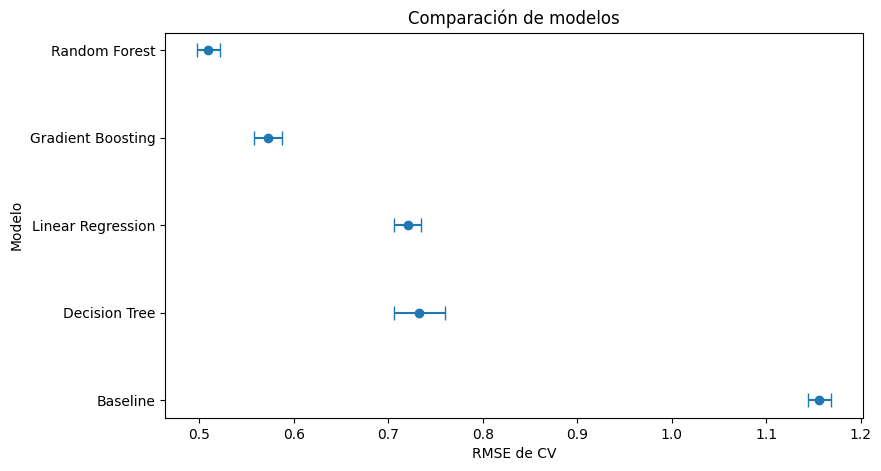

In [12]:
df_plot = df_resultados.sort_values("RMSE_CV", ascending = False)

plt.figure(figsize=(9,5))
plt.errorbar(df_plot["RMSE_CV"],
             df_plot["Modelo"],
             xerr = df_plot["RMSE_SD"],
             fmt = "o",
             capsize = 5
             )
plt.xlabel("RMSE de CV")
plt.ylabel("Modelo")
plt.title("Comparación de modelos")
plt.show()

## 11.9 Observar los resultados fold por fold.

In [13]:
modelos2 = {
    "Random Forest": RandomForestRegressor(n_estimators = 200, random_state=42, n_jobs = -1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2, random_state=42)
}

scoring2 = {
    "RMSE": "neg_root_mean_squared_error"
}


In [14]:
resultados2= []

In [15]:
rmse_model1 = []
rmse_model2 = []

for nombre, modelo in modelos2.items():

    cv_result = cross_validate(
        modelo,
        X_train,
        y_train,
        cv = cv,
        scoring=scoring2,
        n_jobs= -1
    )

    for i in range(1,5):
        score = cv_result["test_RMSE"][i]

        if nombre == "Random Forest":
            rmse_model1.append(score)

        if nombre == "Gradient Boosting":
            rmse_model2.append(score)





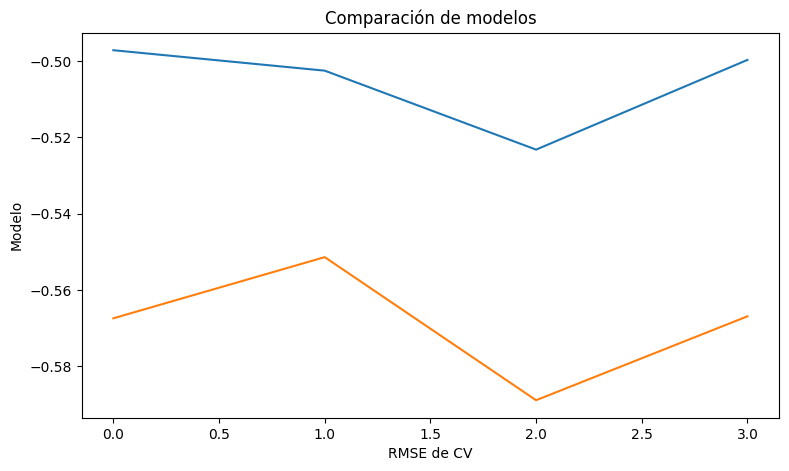

In [16]:
plt.figure(figsize=(9,5))
plt.plot(rmse_model1)
plt.plot(rmse_model2)
plt.xlabel("RMSE de CV")
plt.ylabel("Modelo")
plt.title("Comparación de modelos")
plt.show()

## 11.11 Tuning de Random Forest.

In [17]:
param_rf = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20, 30],
    "max_features": [0.5, 0.75, 1.0],
    "min_samples_leaf": [1,2,4]
}

In [18]:
search_rf = RandomizedSearchCV(
    estimator = RandomForestRegressor(
        random_state=42,
        n_jobs = -1
    ),
    param_distributions= param_rf,
    n_iter = 12, 
    scoring="neg_root_mean_squared_error",
    cv = cv,
    random_state=42,
    n_jobs = -1
)

In [19]:
inicio = perf_counter()
search_rf.fit(X_train, y_train)
tiempo_rf = perf_counter() - inicio

In [20]:
tiempo_rf

338.36639550000837

In [21]:
search_rf.best_params_

{'n_estimators': 400,
 'min_samples_leaf': 1,
 'max_features': 0.5,
 'max_depth': 30}

In [22]:
- search_rf.best_score_

np.float64(0.4986375315567396)

## 11.12 Tuning de Gradient Boosting.

In [23]:
param_gb = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [1,2,3,4],
    "subsample": [0.7, 0.8, 0.9, 1.0]
}


In [24]:
search_gb = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_distributions=param_gb,
    n_iter=12,
    scoring="neg_root_mean_squared_error",
    cv = cv,
    random_state=42,
    n_jobs = -1
)

In [25]:
inicio = perf_counter()
search_gb.fit(X_train, y_train)
tiempo_gb = perf_counter() - inicio

In [26]:
tiempo_gb

118.67634449999605

In [27]:
search_gb.best_params_

{'subsample': 0.8, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.05}

In [28]:
- search_gb.best_score_

np.float64(0.49231818768889457)

## 11.14 El refit ya ocurrió.

In [29]:
modelo_rf_final = search_rf.best_estimator_
modelo_gb_final = search_gb.best_estimator_

## 11.16 Evaluación final.

In [30]:
pred_rf_test = modelo_rf_final.predict(X_test)
pred_gb_test = modelo_gb_final.predict(X_test)

In [31]:
def metricas_regresion(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)

    return mae, rmse, r2

In [32]:
mae_rf, rmse_rf, r2_rf = metricas_regresion(y_test, pred_rf_test)
mae_gb, rmse_gb, r2_gb = metricas_regresion(y_test, pred_gb_test)


In [33]:
resultados_test = pd.DataFrame(
    {
        "Modelo": ["Random Forest", "Gradient Boosting"],
        "MAE_test": [mae_rf, mae_gb],
        "RMSE_test": [rmse_rf, rmse_gb],
        "R2_test": [r2_rf, r2_gb]
    }
)
resultados_test

,Modelo,MAE_test,RMSE_test,R2_test
0,Random Forest,0.320270,0.493625,0.814054
1,Gradient Boosting,0.332126,0.493815,0.813911


## 11.17 CV vs. test.

In [34]:
comparacion_final = pd.DataFrame({
    "Modelo": ["Random Forest", "Gradient Boosting"],
    "RMSE_CV": [-search_rf.best_score_, -search_gb.best_score_],
    "RMSE_test": [rmse_rf, rmse_gb]
}
)
comparacion_final

,Modelo,RMSE_CV,RMSE_test
0,Random Forest,0.498638,0.493625
1,Gradient Boosting,0.492318,0.493815


## 11.18 Predicho vs. observado.

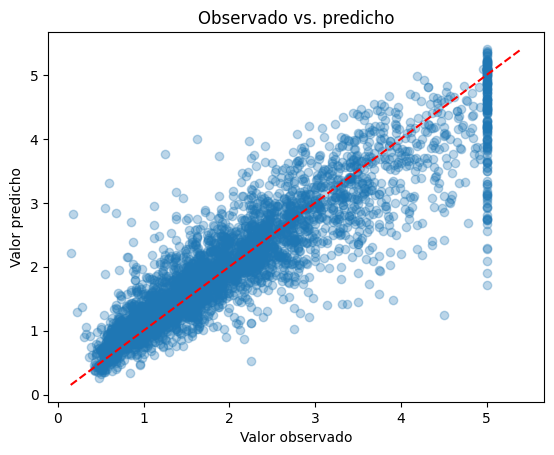

In [35]:
plt.Figure(figsize=(6,6))

plt.scatter(y_test, pred_gb_test, alpha = 0.3)

limites = [min(y_test.min(), pred_gb_test.min()),
           max(y_test.max(), pred_gb_test.max())
           ]

plt.plot(limites, limites, linestyle = "--", color = "red")
plt.xlabel("Valor observado")
plt.ylabel("Valor predicho")

plt.title("Observado vs. predicho")
plt.show()

## 11.19 Residuos.

In [36]:
residuos = y_test - pred_gb_test

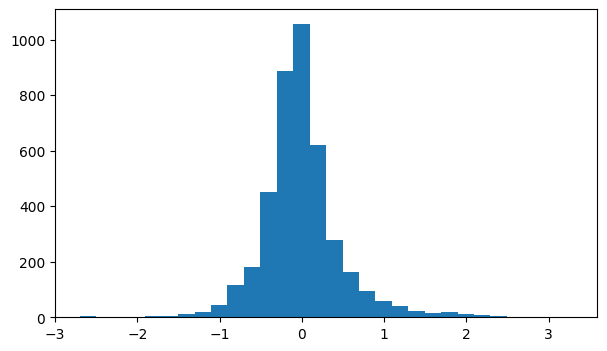

In [37]:
plt.figure(figsize=(7,4))
plt.hist(residuos, bins = 30)
plt.show()

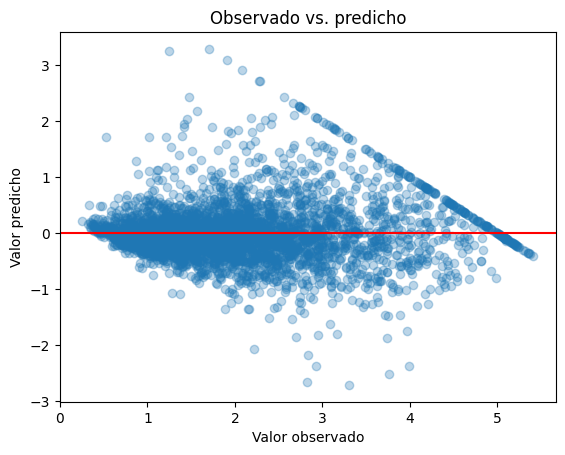

In [38]:
plt.Figure(figsize=(6,6))

plt.scatter(pred_gb_test, residuos, alpha = 0.3)

plt.axhline(y=0, color = "red")

plt.xlabel("Valor observado")
plt.ylabel("Valor predicho")

plt.title("Observado vs. predicho")
plt.show()

## 11.20 ¿Dónde se equivoca más el modelo?

In [39]:
diagnostico = X_test.copy()

diagnostico["y_real"] = y_test
diagnostico["y_pred"] = pred_gb_test
diagnostico["residuo"] = (diagnostico["y_real"] - diagnostico["y_pred"])
diagnostico["error_absoluto"] = (diagnostico["residuo"].abs())

diagnostico.sort_values("error_absoluto", ascending = False).head(10)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,y_real,y_pred,residuo,error_absoluto
10574,1.9659,6.0,4.795455,1.159091,125.0,2.840909,33.72,-117.70,5.00001,1.707870,3.292140,3.292140
19542,1.7679,39.0,5.000000,0.888889,22.0,2.444444,37.63,-120.92,4.50000,1.243524,3.256476,3.256476
12069,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55,5.00001,1.909156,3.090854,3.090854
12389,3.7727,24.0,10.953586,1.848101,473.0,1.995781,33.75,-116.43,5.00001,2.084833,2.915177,2.915177
459,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,5.00001,2.280264,2.719746,2.719746
20325,4.5833,21.0,7.278431,1.082353,863.0,3.384314,34.28,-119.04,5.00001,2.286901,2.713109,2.713109
59,2.5625,2.0,2.771930,0.754386,94.0,1.649123,37.82,-122.29,0.60000,3.304656,-2.704656,2.704656
5887,2.3667,39.0,3.572464,1.217391,259.0,1.876812,34.15,-118.33,0.17500,2.820821,-2.645821,2.645821
20349,7.3004,32.0,5.724138,0.758621,63.0,2.172414,34.17,-119.08,1.25000,3.765107,-2.515107,2.515107
4630,2.3674,20.0,2.740554,1.047859,2919.0,2.450882,34.07,-118.31,5.00001,2.561162,2.438848,2.438848


## 11.21 Error y localización geográfica.

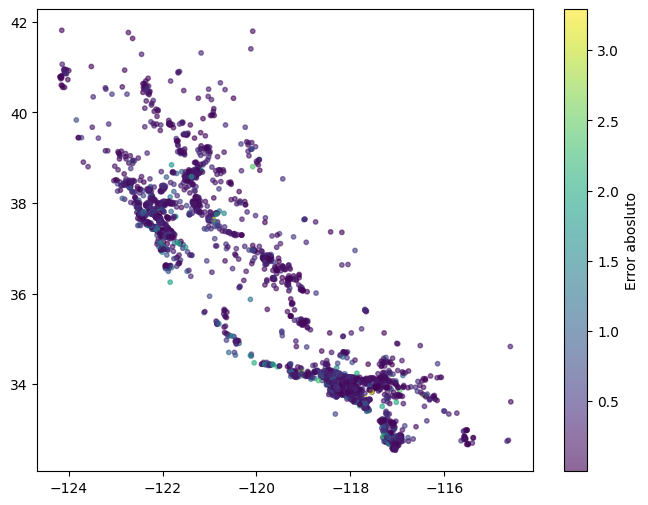

In [40]:
plt.figure(figsize = (8,6))

plt.scatter(diagnostico["Longitude"],
            diagnostico["Latitude"],
            c=diagnostico["error_absoluto"],
            s=10,
            alpha = 0.6)

plt.colorbar(label = "Error abosluto")
plt.show()

## Ejercicio integrador.

Ahora realizarás el mismo flujo utilizando XGBoost.

Importa XGBRegressor, defínelo y utiliza un espacio de parámetros:

In [41]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

param_xgb = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

Realiza un RandomizedSearchCV con n_iter = 15 y 5-fold Cross-Validation. Utiliza como métrica principal neg_root_mean_squared_error.

In [42]:
search_xgb = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_xgb,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv = cv,
    random_state=42,
    n_jobs = -1
)

In [43]:
search_xgb.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'n_estimators': [100, 200, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`

Reporta: 
1) los hiperparámetros seleccionados;

In [44]:
search_xgb.best_params_

{'subsample': 0.7,
 'n_estimators': 500,
 'max_depth': 5,
 'learning_rate': 0.05,
 'colsample_bytree': 0.8}

2) el RMSE promedio de Cross-Validation;

In [45]:
- search_gb.best_score_

np.float64(0.49231818768889457)

3) MAE, RMSE y 𝑅2 sobre test;

In [46]:
modelo_xgb_final = search_xgb.best_estimator_
pred_xgb_test = modelo_xgb_final.predict(X_test)

In [47]:
mae_xgb, rmse_xgb, r2_xgb = metricas_regresion(y_test, pred_xgb_test)

In [48]:
resultados_test2 = pd.DataFrame(
    {
        "Modelo": ["Random Forest", "Gradient Boosting", "Extreme Gradient Boosting"],
        "MAE_test": [mae_rf, mae_gb, mae_xgb],
        "RMSE_test": [rmse_rf, rmse_gb, rmse_xgb],
        "R2_test": [r2_rf, r2_gb, r2_xgb]
    }
)
resultados_test2

,Modelo,MAE_test,RMSE_test,R2_test
0,Random Forest,0.320270,0.493625,0.814054
1,Gradient Boosting,0.332126,0.493815,0.813911
2,Extreme Gradient Boosting,0.301732,0.456000,0.841320


4) una gráfica observado vs. predicho;

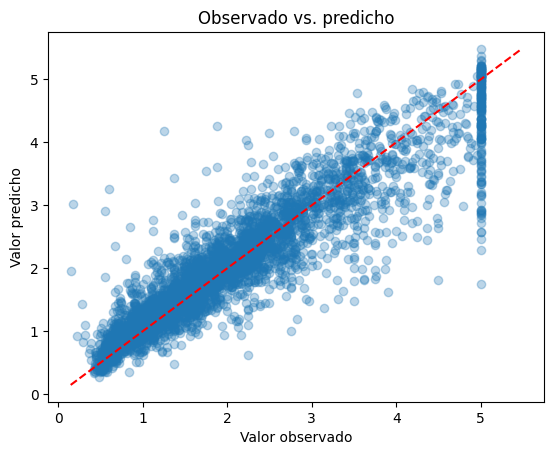

In [49]:
plt.Figure(figsize=(6,6))

plt.scatter(y_test, pred_xgb_test, alpha = 0.3)

limites = [min(y_test.min(), pred_xgb_test.min()),
           max(y_test.max(), pred_xgb_test.max())
           ]

plt.plot(limites, limites, linestyle = "--", color = "red")
plt.xlabel("Valor observado")
plt.ylabel("Valor predicho")

plt.title("Observado vs. predicho")
plt.show()

5) una gráfica de residuos.

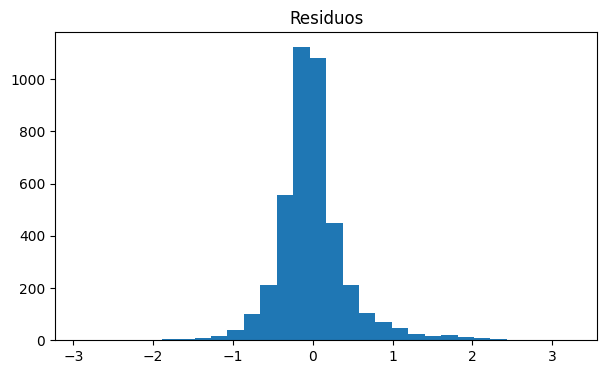

In [50]:
residuos2 = y_test - pred_xgb_test

plt.figure(figsize=(7,4))
plt.hist(residuos2, bins = 30)
plt.title("Residuos")
plt.show()


Finalmente responde:

- ¿El desempeño sobre test fue consistente con el estimado mediante Cross-Validation?

In [51]:
comparacion_final2 = pd.DataFrame({
    "Modelo": ["Random Forest", "Gradient Boosting", "Extreme Gradient Boosting"],
    "RMSE_CV": [-search_rf.best_score_, -search_gb.best_score_, -search_xgb.best_score_],
    "RMSE_test": [rmse_rf, rmse_gb, rmse_xgb]
}
)
comparacion_final2

,Modelo,RMSE_CV,RMSE_test
0,Random Forest,0.498638,0.493625
1,Gradient Boosting,0.492318,0.493815
2,Extreme Gradient Boosting,0.460890,0.456000


    **R:** Sí.

- ¿Qué información adicional obtuviste al observar los residuos que no era visible únicamente con RMSE?

    **R:** Dos modelos pueden tener valores similares de RMSE, pero cometer errores de maneras diferentes.

## Reto adicional: clasificación. 

Hasta ahora toda nuestra práctica se ha desarrollado sobre un problema de regresión.

Sin embargo, el procedimiento general también puede utilizarse en clasificación.

scikit-learn contiene el conjunto Breast Cancer Wisconsin.

In [52]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold

In [53]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(
    as_frame=True
)

X_cancer = cancer.data
y_cancer = cancer.target

In [54]:
cancer.DESCR

'.. _breast_cancer_dataset:\n\nBreast cancer Wisconsin (diagnostic) dataset\n--------------------------------------------\n\n**Data Set Characteristics:**\n\n:Number of Instances: 569\n\n:Number of Attributes: 30 numeric, predictive attributes and the class\n\n:Attribute Information:\n    - radius (mean of distances from center to points on the perimeter)\n    - texture (standard deviation of gray-scale values)\n    - perimeter\n    - area\n    - smoothness (local variation in radius lengths)\n    - compactness (perimeter^2 / area - 1.0)\n    - concavity (severity of concave portions of the contour)\n    - concave points (number of concave portions of the contour)\n    - symmetry\n    - fractal dimension ("coastline approximation" - 1)\n\n    The mean, standard error, and "worst" or largest (mean of the three\n    worst/largest values) of these features were computed for each image,\n    resulting in 30 features.  For instance, field 0 is Mean Radius, field\n    10 is Radius SE, field 

Pregunta

¿Cómo modificarías el flujo utilizado en California Housing para resolver este problema de clasificación?

No es necesario implementar toda la búsqueda.

Identifica al menos:

1) qué modelo utilizarías como baseline;

    **R:** Utilizaría como baseline la clasificación más frecuente.

In [55]:
X_train, X_test, y_train, y_test = train_test_split(X_cancer, y_cancer, test_size=0.20, random_state=42)

In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [57]:
modelos = {
    "Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

2) qué estrategia de Cross-Validation utilizarías;

In [58]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

3) qué métricas reportarías;

    **R:** Yo utilizaría las siguientes:

In [59]:
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall"
}

4) qué modelos compararías;

    **R:** Los siguientes:

In [60]:
resultados = []

for nombre, modelo in modelos.items():

    cv_result = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    resultados.append({
        "Modelo": nombre,

        "Accuracy_CV": cv_result["test_Accuracy"].mean(),
        "Accuracy_SD": cv_result["test_Accuracy"].std(),
        
        "Precision_CV": cv_result["test_Precision"].mean(),
        "Precision_SD": cv_result["test_Precision"].std(),
        
        "Recall_CV": cv_result["test_Recall"].mean(),
        "Recall_SD": cv_result["test_Recall"].std(),
        
        "Tiempo": cv_result["fit_time"].mean()
    })

In [61]:
df_resultados = pd.DataFrame(resultados)

df_resultados

,Modelo,Accuracy_CV,Accuracy_SD,Precision_CV,Precision_SD,Recall_CV,Recall_SD,Tiempo
0,Baseline,0.628571,0.004396,0.628571,0.004396,1.000000,0.000000,0.002781
1,Logistic Regression,0.942857,0.018906,0.948240,0.011176,0.961404,0.023275,0.385186
2,Decision Tree,0.934066,0.029487,0.948820,0.026926,0.947368,0.052043,0.011871
3,Random Forest,0.953846,0.025441,0.955451,0.023504,0.971990,0.023825,0.708220
4,Gradient Boosting,0.940659,0.033040,0.951116,0.016661,0.954386,0.046549,0.950192


5) qué información reservarías hasta la evaluación final.

    **R:** Los datos del conjunto de validación.